# Customer Churn – Stage 2: Clustering Analysis (K-Means)

This notebook continues from `DA_Customer_churn_Preprocessing.ipynb` and covers:

4. **Clustering analysis** – choosing the number of clusters with the elbow method (checked with silhouette scores)
5. **Training a K-Means model** and assigning every customer to a segment
6. **Visualising and labelling clusters** so the segments can be acted on

> **Fix carried over from preprocessing:** in the earlier notebook the `InternetService` cell defined `convert_ser` but applied `convert_gen`, so every value became 0 (you can see `InternetService : [0.]` in the scaled data). This notebook re-encodes from the raw CSV with the correct mapping, so `InternetService` keeps its information.

### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt   # note: pyplot, not plain matplotlib
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42   # fixes K-Means' random start so results are reproducible

### Load the raw dataset
Change `DATA_PATH` to where the CSV lives on your machine, e.g. `'C:/Users/malla/Downloads/Dataset_ATS_v2 (1).csv'`.

In [2]:
DATA_PATH = 'Dataset_ATS_v2 1.csv'
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(7043, 10)


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
0,Female,0,No,1,No,No,DSL,Month-to-month,25,Yes
1,Male,0,No,41,Yes,No,DSL,One year,25,No
2,Female,0,Yes,52,Yes,No,DSL,Month-to-month,19,No
3,Female,0,No,1,Yes,No,DSL,One year,76,Yes
4,Male,0,No,67,Yes,No,Fiber optic,Month-to-month,51,No


### Re-encode categorical columns (with the InternetService fix)

Same encoding as the preprocessing notebook, written with `.map()` on a `.copy()` so there is no `SettingWithCopyWarning` and running the cell twice is safe.

In [3]:
df_enc = df.copy()

yes_no = {'Yes': 1, 'No': 0}
for col in ['Dependents', 'PhoneService', 'MultipleLines', 'Churn']:
    df_enc[col] = df_enc[col].map(yes_no)

df_enc['gender'] = df_enc['gender'].map({'Male': 1, 'Female': 0})
df_enc['InternetService'] = df_enc['InternetService'].map({'Fiber optic': 1, 'DSL': 0})   # fixed
df_enc['Contract'] = df_enc['Contract'].map({'Month-to-month': 0, 'One year': 1, 'Two year': 2})

print(df_enc['InternetService'].value_counts())   # should now show both 0 and 1
df_enc.head()

InternetService
0    3947
1    3096
Name: count, dtype: int64


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn
0,0,0,0,1,0,0,0,0,25,1
1,1,0,0,41,1,0,0,1,25,0
2,0,0,1,52,1,0,0,0,19,0
3,0,0,0,1,1,0,0,1,76,1
4,1,0,0,67,1,0,1,0,51,0


## 4. Clustering analysis

### Which features to cluster on?

K-Means groups customers by distance, so the features we pick decide what "similar" means. We cluster on the two **behavioural / value** features:

- **tenure** – how long the customer has stayed
- **MonthlyCharges** – how much they pay

Reasons:
- These are the features a business actually segments on (customer lifetime vs. spend), so the clusters are easy to name and act on.
- Mixing in many 0/1 columns (gender, PhoneService…) creates artificial "corners" in the data and K-Means splits on them instead of on real behaviour – in testing, all 9 features gave silhouette scores below 0.19, versus 0.48 for these two.
- **Churn is deliberately left out.** Clusters are built without knowing who churned; afterwards we check the churn rate of each cluster. If segments differ a lot in churn, the segmentation is useful.

Both features are standardised (mean 0, std 1) so that MonthlyCharges (18–119) doesn't outweigh tenure (0–72).

In [4]:
features = ['tenure', 'MonthlyCharges']

scaler_clust = StandardScaler()
X_clust = scaler_clust.fit_transform(df_enc[features])

pd.DataFrame(X_clust, columns=features).describe().round(2)

,tenure,MonthlyCharges
count,7043.00,7043.00
mean,-0.00,-0.00
std,1.00,1.00
min,-1.32,-1.55
25%,-0.95,-0.96
50%,-0.14,0.17
75%,0.92,0.84
max,1.61,1.80


### Elbow method

We train K-Means for k = 1 to 10 and record the **inertia (WCSS)** – the total squared distance of points to their cluster centre. Inertia always falls as k grows; the "elbow" is where adding another cluster stops giving a big improvement.

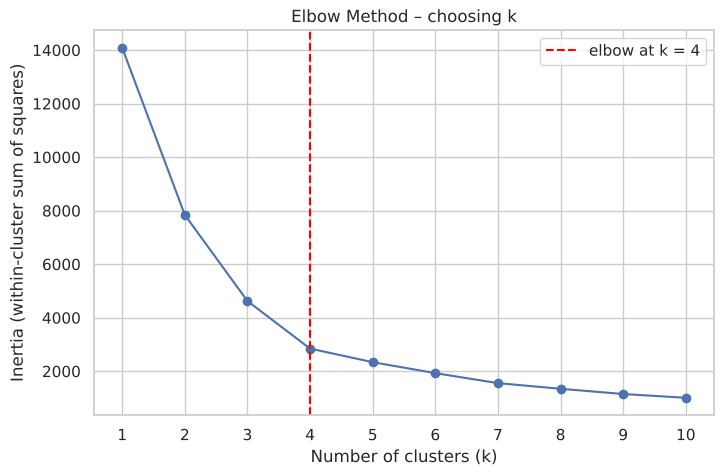

,k,inertia,drop_from_previous
0,1,14086.0,NaN
1,2,7841.0,6245.0
2,3,4622.0,3219.0
3,4,2846.0,1776.0
4,5,2339.0,507.0
5,6,1929.0,410.0
6,7,1556.0,373.0
7,8,1345.0,211.0
8,9,1149.0,196.0
9,10,1008.0,141.0


In [5]:
k_range = range(1, 11)
inertia = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    km.fit(X_clust)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertia, marker='o')
plt.axvline(4, color='red', linestyle='--', label='elbow at k = 4')
plt.title('Elbow Method – choosing k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (within-cluster sum of squares)')
plt.xticks(list(k_range))
plt.legend()
plt.show()

pd.DataFrame({'k': list(k_range), 'inertia': np.round(inertia, 0),
              'drop_from_previous': np.round(-np.diff([np.nan] + inertia), 0)})

### Confirming with silhouette score

The elbow can be subjective, so we cross-check with the **silhouette score** (−1 to 1; higher = clusters are tighter and better separated).

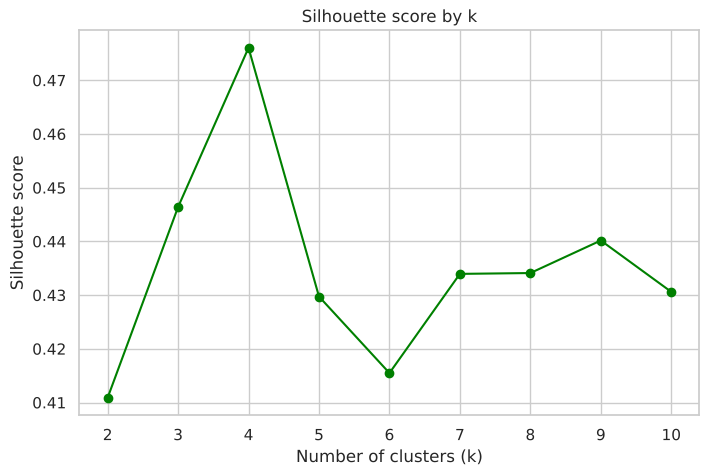

Highest silhouette at k = 4 (0.476)


In [6]:
sil = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_clust)
    sil[k] = silhouette_score(X_clust, labels)

plt.figure(figsize=(8, 5))
plt.plot(list(sil.keys()), list(sil.values()), marker='o', color='green')
plt.title('Silhouette score by k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.xticks(list(sil.keys()))
plt.show()

best_k = max(sil, key=sil.get)
print('Highest silhouette at k =', best_k, f'({sil[best_k]:.3f})')

**Conclusion:** the inertia curve bends at **k = 4** (big drops up to 4, small ones after), and k = 4 also has the highest silhouette score. We use **4 clusters**.

## 5. Train the K-Means model

In [7]:
OPTIMAL_K = 4
kmeans = KMeans(n_clusters=OPTIMAL_K, n_init=10, random_state=RANDOM_STATE)
df_enc['Cluster'] = kmeans.fit_predict(X_clust)

df_enc['Cluster'].value_counts().sort_index()

Cluster
0    2202
1    1733
2    1948
3    1160
Name: count, dtype: int64

### Cluster centres in original units
The model stores centres in scaled units; `inverse_transform` turns them back into months and dollars.

In [8]:
centres = pd.DataFrame(scaler_clust.inverse_transform(kmeans.cluster_centers_),
                       columns=features).round(1)
centres.index.name = 'Cluster'
centres

,tenure,MonthlyCharges
Cluster,,
0,14.8,81.2
1,10.5,32.5
2,58.8,93.1
3,54.1,34.2


## 6. Profile and label the clusters

First, the average profile of each cluster – including features **not** used for clustering, and the churn rate.

In [9]:
profile = df_enc.groupby('Cluster').agg(
    customers=('Churn', 'size'),
    avg_tenure=('tenure', 'mean'),
    avg_monthly_charges=('MonthlyCharges', 'mean'),
    churn_rate=('Churn', 'mean'),
    pct_fiber=('InternetService', 'mean'),
    pct_month_to_month=('Contract', lambda s: (s == 0).mean()),
    pct_senior=('SeniorCitizen', 'mean'),
    pct_dependents=('Dependents', 'mean'),
).round(2)
profile

,customers,avg_tenure,avg_monthly_charges,churn_rate,pct_fiber,pct_month_to_month,pct_senior,pct_dependents
Cluster,,,,,,,,
0,2202,14.81,81.23,0.49,0.43,0.56,0.23,0.20
1,1733,10.48,32.49,0.24,0.44,0.54,0.07,0.30
2,1948,58.76,93.08,0.16,0.45,0.55,0.22,0.33
3,1160,54.10,34.15,0.05,0.44,0.54,0.08,0.44


### Assign business labels

Labels are derived from each centre (above/below the overall average tenure and charges) rather than typed against cluster numbers, because K-Means numbering can change between runs.

In [10]:
tenure_cut = df_enc['tenure'].mean()
charge_cut = df_enc['MonthlyCharges'].mean()

def name_cluster(row):
    long_stay = row['tenure'] >= tenure_cut
    high_spend = row['MonthlyCharges'] >= charge_cut
    if not long_stay and high_spend:
        return 'New High-Spenders (At Risk)'
    if not long_stay and not high_spend:
        return 'New Budget Customers'
    if long_stay and high_spend:
        return 'Loyal Premium Customers'
    return 'Loyal Budget Customers'

cluster_names = centres.apply(name_cluster, axis=1).to_dict()
df_enc['Segment'] = df_enc['Cluster'].map(cluster_names)
profile.insert(0, 'Segment', profile.index.map(cluster_names))
profile.sort_values('churn_rate', ascending=False)

,Segment,customers,avg_tenure,avg_monthly_charges,churn_rate,pct_fiber,pct_month_to_month,pct_senior,pct_dependents
Cluster,,,,,,,,,
0,New High-Spenders (At Risk),2202,14.81,81.23,0.49,0.43,0.56,0.23,0.20
1,New Budget Customers,1733,10.48,32.49,0.24,0.44,0.54,0.07,0.30
2,Loyal Premium Customers,1948,58.76,93.08,0.16,0.45,0.55,0.22,0.33
3,Loyal Budget Customers,1160,54.10,34.15,0.05,0.44,0.54,0.08,0.44


### Visualise the clusters

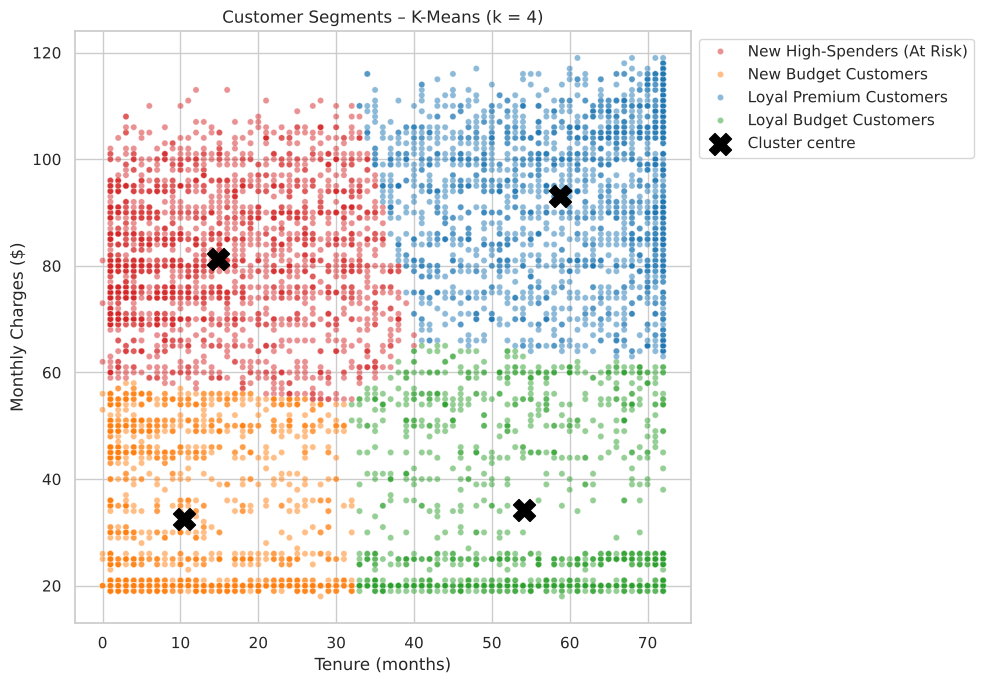

In [11]:
seg_order = ['New High-Spenders (At Risk)', 'New Budget Customers',
             'Loyal Premium Customers', 'Loyal Budget Customers']
palette = dict(zip(seg_order, ['#d62728', '#ff7f0e', '#1f77b4', '#2ca02c']))

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df_enc, x='tenure', y='MonthlyCharges', hue='Segment',
                hue_order=seg_order, palette=palette, alpha=0.5, s=20)
plt.scatter(centres['tenure'], centres['MonthlyCharges'], c='black', marker='X',
            s=250, label='Cluster centre')
plt.title('Customer Segments – K-Means (k = 4)')
plt.xlabel('Tenure (months)')
plt.ylabel('Monthly Charges ($)')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

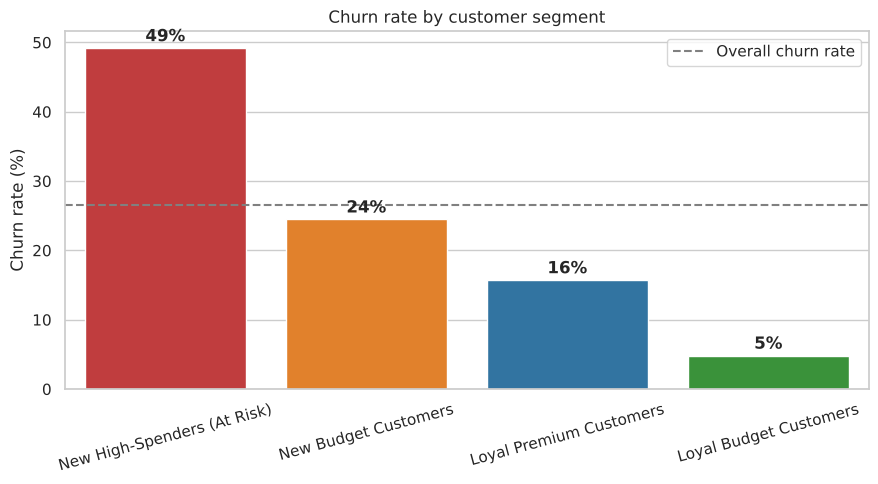

In [12]:
churn_by_seg = df_enc.groupby('Segment')['Churn'].mean().reindex(seg_order) * 100

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=churn_by_seg.index, y=churn_by_seg.values,
                 hue=churn_by_seg.index, palette=palette, legend=False)
ax.axhline(df_enc['Churn'].mean() * 100, color='grey', linestyle='--', label='Overall churn rate')
for i, v in enumerate(churn_by_seg.values):
    ax.text(i, v + 1, f'{v:.0f}%', ha='center', fontweight='bold')
plt.title('Churn rate by customer segment')
plt.ylabel('Churn rate (%)')
plt.xlabel('')
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

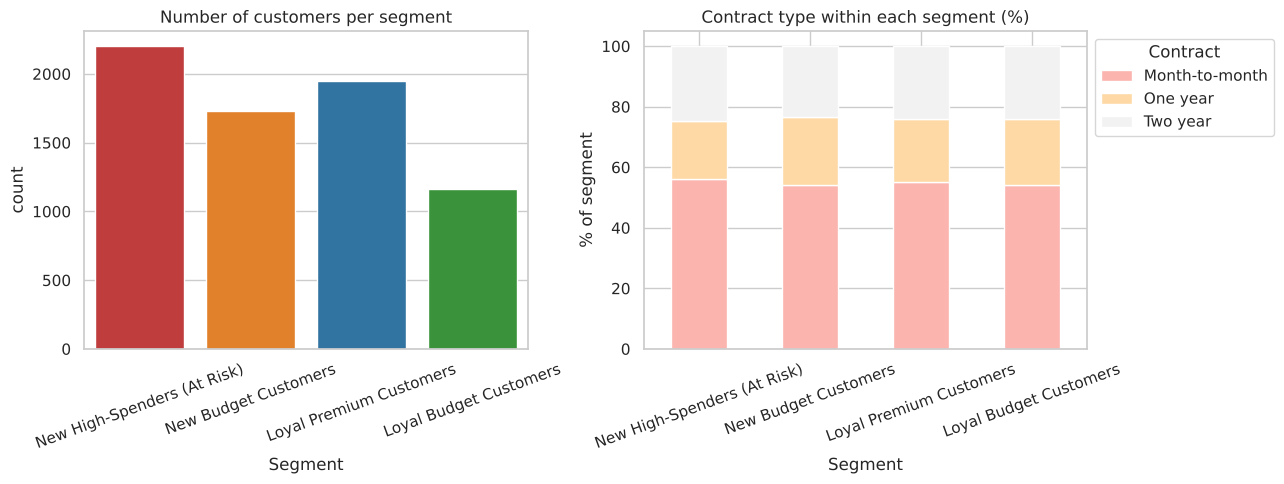

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=df_enc, x='Segment', order=seg_order, hue='Segment',
              palette=palette, legend=False, ax=axes[0])
axes[0].set_title('Number of customers per segment')
axes[0].tick_params(axis='x', rotation=20)

contract_mix = (pd.crosstab(df_enc['Segment'], df['Contract'], normalize='index')
                  .reindex(seg_order) * 100)
contract_mix.plot(kind='bar', stacked=True, ax=axes[1], colormap='Pastel1')
axes[1].set_title('Contract type within each segment (%)')
axes[1].set_ylabel('% of segment')
axes[1].tick_params(axis='x', rotation=20)
axes[1].legend(title='Contract', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

### Interpretation and actions

| Segment | Who they are | Churn | Suggested action |
|---|---|---|---|
| **New High-Spenders (At Risk)** | ~15 months tenure, ~$81/month | **~49%** – the main churn problem | Onboarding check-ins, discounts for moving to 1- or 2-year contracts, service-quality follow-up |
| **New Budget Customers** | ~10 months, ~$32/month | ~24% | Nurture: bundle offers, early loyalty perks |
| **Loyal Premium Customers** | ~59 months, ~$93/month | ~16% | Highest value – VIP treatment, retention priority, upgrade offers |
| **Loyal Budget Customers** | ~54 months, ~$34/month | ~5% | Stable – low-cost upsell opportunities |

Key takeaway: churn is concentrated in **new customers who pay a lot**. Nearly half of that segment leaves, so it is the first place to direct retention spend.

*(Exact figures are printed in the profile table above; they will match if you keep `random_state=42`.)*

### Save results
Saves the labelled dataset, plus the model and its scaler so new customers can be assigned to a segment later.

In [14]:
out = df.copy()
out['Cluster'] = df_enc['Cluster']
out['Segment'] = df_enc['Segment']
out.to_csv('customer_segments.csv', index=False)

joblib.dump(kmeans, 'kmeans_model.pkl')
joblib.dump(scaler_clust, 'scaler_clustering.pkl')
print('Saved customer_segments.csv, kmeans_model.pkl, scaler_clustering.pkl')

Saved customer_segments.csv, kmeans_model.pkl, scaler_clustering.pkl


### Example: segment a new customer

In [15]:
new_customer = pd.DataFrame({'tenure': [3], 'MonthlyCharges': [95]})
cluster_id = kmeans.predict(scaler_clust.transform(new_customer))[0]
print('Cluster', cluster_id, '->', cluster_names[cluster_id])

Cluster 0 -> New High-Spenders (At Risk)
